1. Import library dan pemanggilan file

In [18]:
from pathlib import Path
from functools import lru_cache
from collections import Counter
import ast
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from rank_bm25 import BM25Okapi
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory
from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory

pd.set_option('display.max_colwidth', 120)

CWD = Path.cwd().resolve()
REQUIRED = ('corpus_faq.csv','kamus_normalisasi.csv','queries_dev.csv','queries_test.csv')
ROOT = next((p for p in (CWD, *CWD.parents) if all((p/f).is_file() for f in REQUIRED)), None)
if ROOT is None:
    raise FileNotFoundError(f'Folder proyek berisi {REQUIRED} tidak ditemukan dari {CWD}')
OUTPUT_DIR = ROOT / 'Eksperiment3' / 'hasil_exp3'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

corpus = pd.read_csv(ROOT/'corpus_faq.csv', dtype={'doc_id':'string'})
kamus = pd.read_csv(ROOT/'kamus_normalisasi.csv')
dev_df = pd.read_csv(ROOT/'queries_dev.csv', dtype={'query_id':'string','relevant_doc_id':'string'})
test_df = pd.read_csv(ROOT/'queries_test.csv', dtype={'query_id':'string','relevant_doc_id':'string'})

for nama,df,cols in [
    ('corpus',corpus,['doc_id','pertanyaan_baku','jawaban']),
    ('kamus',kamus,['tidak_baku','baku']),
    ('dev',dev_df,['query_id','query_text','gaya_kueri','relevant_doc_id']),
    ('test',test_df,['query_id','query_text','gaya_kueri','relevant_doc_id'])
]:
    kurang = set(cols)-set(df.columns)
    if kurang: raise ValueError(f'{nama}: kolom hilang {sorted(kurang)}')
if corpus['doc_id'].duplicated().any(): raise ValueError('doc_id dalam corpus duplikat')
if dev_df['query_id'].duplicated().any() or test_df['query_id'].duplicated().any():
    raise ValueError('query_id duplikat di dev/test')
if set(dev_df['query_id']) & set(test_df['query_id']):
    raise ValueError('Dev/test tumpang tindih; gunakan split asli')

K1, B = 1.5, 0.75
THRESHOLDS = [0,1,2,3]
PERSENTIL_DEV_BENAR = 0.05
JALANKAN_TEST_FINAL = True  # Set False jika belum masuk tahap evaluasi final
ORDER = ['formal','informal','singkatan','parafrase','typo']
KONFIG = ['Baseline','Kamus','Damerau','Gabungan']
LABEL = {
    'Baseline':'Baseline (BM25 tanpa koreksi)',
    'Kamus':'BM25 + Normalisasi Kamus',
    'Damerau':'BM25 + Damerau-Levenshtein',
    'Gabungan':'BM25 + Kamus + Damerau-Levenshtein'
}
print('ROOT:',ROOT,'\nOUTPUT:',OUTPUT_DIR)
print(f'Corpus={len(corpus)}, Kamus={len(kamus)}, Dev={len(dev_df)}, Test={len(test_df)}')


ROOT: D:\Folder KULIAH\Sistem Temu Kembali\Artikel (1) 
OUTPUT: D:\Folder KULIAH\Sistem Temu Kembali\Artikel (1)\Eksperiment3\hasil_exp3
Corpus=40, Kamus=73, Dev=166, Test=499


2. Preprocessing standar, indeks BM25, dan kosakata referensi

In [19]:
stemmer = StemmerFactory().create_stemmer()
stopwords_id = set(StopWordRemoverFactory().get_stop_words())
@lru_cache(maxsize=None)
def stem_cached(token): return stemmer.stem(token)

def case_fold(text): return str(text).lower()
def clean_regex(text):
    text = re.sub(r'[^a-z0-9\s]',' ',text)
    return re.sub(r'\s+',' ',text).strip()
def tokenize(text): return text.split()
def remove_stopwords(tokens): return [t for t in tokens if t not in stopwords_id]
def raw_tokens(text): return tokenize(clean_regex(case_fold(text)))
def preprocess_standard(text):
    return [stem_cached(t) for t in remove_stopwords(raw_tokens(text))]

corpus['teks_indeks'] = corpus['pertanyaan_baku'].fillna('').astype(str) + ' ' + corpus['jawaban'].fillna('').astype(str)
corpus_tokens = corpus['teks_indeks'].apply(preprocess_standard).tolist()
doc_ids = corpus['doc_id'].astype(str).tolist()
faq_id_set = set(doc_ids)
for nama,df in [('dev',dev_df),('test',test_df)]:
    tidak_ada = set(df['relevant_doc_id'].astype(str))-faq_id_set
    if tidak_ada: raise ValueError(f'{nama}: label relevansi tidak dikenal: {sorted(tidak_ada)}')

bm25 = BM25Okapi(corpus_tokens, k1=K1, b=B)
corpus_surface_tokens = [t for text in corpus['teks_indeks'] for t in remove_stopwords(raw_tokens(text))]
corpus_stemmed_tokens = [t for tokens in corpus_tokens for t in tokens]
vocab_freq = Counter(corpus_surface_tokens+corpus_stemmed_tokens)
vocab_acuan = set(vocab_freq) | stopwords_id
# Mengurutkan kosakata untuk hasil konsisten saat beberapa kandidat punya jarak/frekuensi sama.
vocab_urut = sorted(vocab_acuan)

# Validasi praproses standar terhadap split baseline yang telah disimpan.
for nama,df in [('dev',dev_df),('test',test_df)]:
    if 'tokens_baseline' in df.columns:
        n_beda = sum(preprocess_standard(r.query_text) != ast.literal_eval(str(r.tokens_baseline))
                     for r in df.itertuples(index=False))
        print(f'Perbedaan token baseline ({nama}): {n_beda}')
        if n_beda:
            raise ValueError('Token preprocessing berbeda dengan baseline. Periksa versi Sastrawi dan langkah preprocessing.')
print(f'FAQ={len(doc_ids)}, kosa kata acuan={len(vocab_acuan)}, k1={K1}, b={B}')


Perbedaan token baseline (dev): 0
Perbedaan token baseline (test): 0
FAQ=40, kosa kata acuan=564, k1=1.5, b=0.75


3. Kamus, Damerau-Levenshtein (OSA), dan konfigurasi gabungan

In [20]:
# Kamus mengikuti Exp1: padanan kosong/ambigu dilewati, frasa panjang didahulukan.
pasangan_kamus, entri_dilewati, seen = [], [], {}
for nomor,row in kamus.iterrows():
    asal_raw, baku_raw = row['tidak_baku'], row['baku']
    if pd.isna(asal_raw) or pd.isna(baku_raw) or '/' in str(baku_raw):
        entri_dilewati.append((nomor, asal_raw, baku_raw)); continue
    asal = tuple(raw_tokens(asal_raw))
    tujuan = tuple(raw_tokens(baku_raw))
    if not asal or not tujuan:
        entri_dilewati.append((nomor, asal_raw, baku_raw)); continue
    if asal in seen and seen[asal] != tujuan:
        raise ValueError(f'Kamus ambigu untuk {asal}')
    if asal not in seen:
        pasangan_kamus.append((asal,tujuan))
        seen[asal] = tujuan
pasangan_kamus.sort(key=lambda p:(-len(p[0]),p[0]))

def ganti_kamus_dengan_proteksi(tokens):
    hasil, proteksi, log = [], [], []
    i = 0
    while i < len(tokens):
        cocok = False
        for asal,tujuan in pasangan_kamus:
            n = len(asal)
            if tuple(tokens[i:i+n]) == asal:
                hasil.extend(tujuan)
                proteksi.extend([True]*len(tujuan))
                log.append({'asal':' '.join(asal), 'tujuan':' '.join(tujuan),
                            'n_token_terkoreksi':sum(t not in stopwords_id for t in asal)})
                i += n; cocok = True; break
        if not cocok:
            hasil.append(tokens[i]); proteksi.append(False); i += 1
    return hasil, proteksi, log

# Mengikuti jenis operasi Exp2, yakni restricted Damerau-Levenshtein (OSA).
@lru_cache(maxsize=None)
def damerau_levenshtein_distance(s1,s2):
    m,n = len(s1),len(s2)
    d = [[0]*(n+1) for _ in range(m+1)]
    for i in range(m+1): d[i][0] = i
    for j in range(n+1): d[0][j] = j
    for i in range(1,m+1):
        for j in range(1,n+1):
            cost = (s1[i-1] != s2[j-1])
            d[i][j] = min(d[i-1][j]+1, d[i][j-1]+1, d[i-1][j-1]+cost)
            if i>1 and j>1 and s1[i-1]==s2[j-2] and s1[i-2]==s2[j-1]:
                d[i][j] = min(d[i][j],d[i-2][j-2]+1)
    return d[m][n]

@lru_cache(maxsize=None)
def cari_kandidat_terdekat(token, maks_jarak):
    # Membatasi kandidat panjang tidak mengubah koreksi yang berjarak <= maks_jarak.
    terbaik, jarak_min, frek_terbaik = token, float('inf'), -1
    for cand in vocab_urut:
        if abs(len(token)-len(cand)) > maks_jarak: continue
        jarak = damerau_levenshtein_distance(token,cand)
        frek = vocab_freq[cand]
        if jarak < jarak_min or (jarak == jarak_min and frek > frek_terbaik):
            terbaik, jarak_min, frek_terbaik = cand, jarak, frek
    return terbaik, jarak_min

def koreksi_token_damerau(token, threshold):
    if threshold <= 0 or token.isdigit() or len(token)<3 or token in vocab_acuan or stem_cached(token) in vocab_acuan:
        return token,0,False
    batas = min(threshold,1) if len(token)<=4 else threshold
    kandidat, jarak = cari_kandidat_terdekat(token, batas)
    if jarak <= batas and kandidat != token:
        return kandidat,jarak,True
    return token,jarak,False

def preprocess_kueri(text, metode, threshold=0):
    awal = raw_tokens(text)
    log_kamus, log_dl = [], []
    if metode in ('Kamus','Gabungan'):
        tengah, proteksi, log_kamus = ganti_kamus_dengan_proteksi(awal)
    else:
        tengah, proteksi = list(awal), [False]*len(awal)

    # Seperti Exp2: hapus stopword SEBELUM Damerau jika hanya koreksi ejaan;
    # seperti Exp3: kamus lebih dulu, lalu Damerau pada token non-kamus.
    if metode == 'Damerau':
        pairs = [(t,p) for t,p in zip(tengah,proteksi) if t not in stopwords_id]
        tengah = [t for t,_ in pairs]
        proteksi = [p for _,p in pairs]
    if metode in ('Damerau','Gabungan'):
        terkoreksi = []
        for token,dilindungi in zip(tengah,proteksi):
            if dilindungi:
                terkoreksi.append(token); continue
            baru,jarak,ubah = koreksi_token_damerau(token,threshold)
            terkoreksi.append(baru)
            if ubah: log_dl.append({'asal':token,'tujuan':baru,'jarak':jarak})
        tengah = terkoreksi
    token_final = [stem_cached(t) for t in remove_stopwords(tengah)]
    return token_final, log_kamus, log_dl

print(f'Kamus valid: {len(pasangan_kamus)}; dilewati: {len(entri_dilewati)}')
if entri_dilewati:
    display(pd.DataFrame(entri_dilewati,columns=['baris_csv','tidak_baku','baku']))


Kamus valid: 68; dilewati: 5


,baris_csv,tidak_baku,baku
0,64,mi,NaN
1,65,ki,NaN
2,66,ji,NaN
3,67,ta,kita/anda
4,69,tabe,permisi/maaf


4. Contoh normalisasi pada development set

In [21]:
contoh = dev_df[dev_df['gaya_kueri'].isin(['singkatan','informal','typo'])].head(9)
contoh_rows = []
for r in contoh.itertuples(index=False):
    tokens,log_k,log_d = preprocess_kueri(r.query_text,'Gabungan',threshold=2)
    contoh_rows.append({
        'ID':r.query_id,'Gaya':r.gaya_kueri,'Kueri':r.query_text,
        'Kamus':' | '.join(f"{x['asal']} -> {x['tujuan']}" for x in log_k),
        'Damerau':' | '.join(f"{x['asal']} -> {x['tujuan']} (d={x['jarak']})" for x in log_d),
        'Token final':' '.join(tokens)
    })
display(pd.DataFrame(contoh_rows))


,ID,Gaya,Kueri,Kamus,Damerau,Token final
0,Q0038,informal,teman kelompok ku masih belum join dipengelompokan tapi sudah disetujui oleh admin,,,teman kelompok ku join kelompok tuju admin
1,Q0182,informal,"mau tanya, apa untuk mahasiswa Prodi Teknik Komputer yang sedang melaksanakan PI, mata kuliah PI wajib diprogramkan ...",pi -> praktik industri | pi -> praktik industri,tanya -> tanda (d=1) | sedang -> bidang (d=2) | depan -> kapan (d=2),mau tanda apa mahasiswa prodi teknik komputer bidang laksana praktik industri mata kuliah praktik industri wajib pro...
2,Q0380,typo,"nama aKprodi di dokumen IA masih menggunaakn nama lama padahal sudah ada pergantina, apakah perlu disesuaiakn",ia -> implementation arrangement,akprodi -> kaprodi (d=1) | menggunaakn -> menggunakan (d=1) | pergantina -> pergantian (d=1) | disesuaiakn -> disesu...,nama kaprodi dokumen implementation arrangement guna nama lama padahal ganti perlu sesuai
3,Q0042,informal,"tempat pi ku ga ada di list sipi, gmn caranya nambahin",pi -> praktik industri | ga -> tidak | sipi -> sistem informasi praktik industri | gmn -> bagaimana,nambahin -> tambahan (d=2),tempat praktik industri ku list sistem informasi praktik industri bagaimana cara tambah
4,Q0385,singkatan,"mhn info, nomor surat SPK dan IA didapatkan dr mn",spk -> surat pernyataan kerjasama | ia -> implementation arrangement | dr -> dari | mn -> mana,,mhn info nomor surat surat nyata kerjasama implementation arrangement dapat mana
5,Q0388,informal,"ibu, nomor surat SPK dan IA didapatkan dari mana",spk -> surat pernyataan kerjasama | ia -> implementation arrangement,ibu -> itu (d=1),nomor surat surat nyata kerjasama implementation arrangement dapat mana
6,Q0490,typo,berapa lama batsa waktu pelaksanaan semianr PI setelah hari penarikan,pi -> praktik industri,batsa -> batas (d=1) | semianr -> seminar (d=1),berapa lama batas waktu laksana seminar praktik industri hari tari
7,Q0572,typo,niai PI yang diupload itu nilai dari temat PI atau nilai sesudah semnar,pi -> praktik industri | pi -> praktik industri | sesudah -> setelah,niai -> nilai (d=1) | temat -> tempat (d=1) | semnar -> seminar (d=1),nilai praktik industri diupload nilai tempat praktik industri nilai seminar
8,Q0009,singkatan,sdh daftar ulang pake email beda ttp tdk ada masuk di spam,sdh -> sudah | ttp -> tetap | tdk -> tidak,,daftar ulang pake email beda tetap masuk spam


5. Evaluasi, tuning Damerau pada dev, dan threshold fallback BM25

In [22]:
def evaluasi_detail(df, metode, threshold=0):
    if df.empty: raise ValueError('Dataset evaluasi kosong')
    rec = []
    for r in df.itertuples(index=False):
        tokens, log_k, log_d = preprocess_kueri(r.query_text,metode,threshold)
        skor = bm25.get_scores(tokens)
        urut = np.argsort(skor)[::-1]  # Sama seperti Exp1 dan Exp2
        ranking = [doc_ids[i] for i in urut]
        relevan = str(r.relevant_doc_id)
        rank = ranking.index(relevan)+1
        n_k = sum(x['n_token_terkoreksi'] for x in log_k)
        n_d = len(log_d)
        total_token = len(remove_stopwords(raw_tokens(r.query_text)))
        rec.append({
            'query_id':str(r.query_id),'gaya_kueri':str(r.gaya_kueri),
            'query_text':r.query_text,'relevant_doc_id':relevan,
            'prediksi_top1':ranking[0], 'peringkat_benar':rank,
            'skor_top1':float(skor[urut[0]]),
            'hit1':int(rank==1),'hit3':int(rank<=3),'hit5':int(rank<=5),
            'rr':1.0/rank,'n_kamus':n_k,'n_damerau':n_d,
            'n_total_tokens':total_token,'n_terkoreksi':n_k+n_d,
            'normalisasi_kamus':' | '.join(f"{x['asal']} -> {x['tujuan']}" for x in log_k),
            'koreksi_damerau':' | '.join(f"{x['asal']} -> {x['tujuan']} (d={x['jarak']})" for x in log_d),
            'tokens_bm25':' '.join(tokens)
        })
    return pd.DataFrame(rec)

def ringkas(detail, T_BM25=None):
    if len(detail)==0: raise ValueError('Detail kosong')
    result = {
        'Hit@1':float(detail['hit1'].mean()),
        'Hit@3':float(detail['hit3'].mean()),
        'Hit@5':float(detail['hit5'].mean()),
        'MRR':float(detail['rr'].mean()),
        'Token_Terkoreksi':int(detail['n_terkoreksi'].sum()),
        'Rasio_Koreksi':float(detail['n_terkoreksi'].sum()/max(detail['n_total_tokens'].sum(),1)),
        'n':int(len(detail))
    }
    if T_BM25 is not None:
        result['Fallback Rate'] = float((detail['skor_top1']<T_BM25).mean())
        result['Kueri_Fallback'] = int((detail['skor_top1']<T_BM25).sum())
    return result

# Kalibrasi sekali dari baseline-dev, sebelum melihat test.
detail_dev_baseline = evaluasi_detail(dev_df,'Baseline')
skor_dev_benar = detail_dev_baseline.loc[detail_dev_baseline['hit1']==1,'skor_top1']
if skor_dev_benar.empty:
    raise ValueError('Tidak ada baseline top-1 benar pada dev untuk menentukan T_BM25.')
T_BM25 = float(skor_dev_benar.quantile(PERSENTIL_DEV_BENAR))
print(f'T skor BM25 tetap dari dev = {T_BM25:.6f} (persentil {PERSENTIL_DEV_BENAR:.0%}, baseline benar)')
print('Ini adalah heuristik kalibrasi, bukan ukuran penolakan kueri out-of-scope.')

# Tuning terpisah: Exp2 (Damerau saja) dan Exp3 (Kamus + Damerau).
detail_dev = {'Baseline':detail_dev_baseline, 'Kamus':evaluasi_detail(dev_df,'Kamus')}
tuning_records = []
for metode in ('Damerau','Gabungan'):
    for d in THRESHOLDS:
        hasil = evaluasi_detail(dev_df,metode,d)
        detail_dev[(metode,d)] = hasil
        metr = ringkas(hasil,T_BM25)
        sub_typo = hasil[hasil['gaya_kueri']=='typo']
        tuning_records.append({
            'Metode':metode,'Threshold':d,
            **metr,
            'Hit@1_Typo':float(sub_typo['hit1'].mean()) if len(sub_typo) else np.nan,
            'MRR_Typo':float(sub_typo['rr'].mean()) if len(sub_typo) else np.nan,
            'Token_Damerau':int(hasil['n_damerau'].sum())
        })
tuning_df = pd.DataFrame(tuning_records)
display(tuning_df.round(4))

def pilih_d(metode):
    # d=0 kontrol tanpa Damerau; pilih kombinasi aktif d>=1 dari dev.
    pilihan = tuning_df[(tuning_df['Metode']==metode)&(tuning_df['Threshold']>0)].copy()
    pilihan = pilihan.sort_values(['MRR','Hit@1','Token_Damerau','Threshold'],ascending=[False,False,True,True])
    return int(pilihan.iloc[0]['Threshold'])

best_d2 = pilih_d('Damerau')
best_threshold = pilih_d('Gabungan')
print(f'Threshold terpilih Damerau saja (Exp2): {best_d2}')
print(f'Threshold terpilih Kamus+Damerau (Exp3): {best_threshold}')
print('d=0 adalah kontrol (untuk gabungan: kamus saja), bukan threshold final wajib.')

tuning_df.to_csv(OUTPUT_DIR/'hasil_tuning_damerau_dev.csv',index=False)
pd.DataFrame([{'Metode_Kalibrasi':'Persentil skor BM25 top1 benar baseline DEV',
               'Persentil':PERSENTIL_DEV_BENAR,'T_BM25':T_BM25,
               'Jumlah_benar_dev':len(skor_dev_benar), 'best_d2':best_d2,
               'best_d3':best_threshold}]).to_csv(OUTPUT_DIR/'parameter_tuning_dev.csv',index=False)


T skor BM25 tetap dari dev = 8.385280 (persentil 5%, baseline benar)
Ini adalah heuristik kalibrasi, bukan ukuran penolakan kueri out-of-scope.


,Metode,Threshold,Hit@1,Hit@3,Hit@5,MRR,Token_Terkoreksi,Rasio_Koreksi,n,Fallback Rate,Kueri_Fallback,Hit@1_Typo,MRR_Typo,Token_Damerau
0,Damerau,0,0.9398,0.9819,0.988,0.9620,0,0.0000,166,0.1084,18,0.875,0.9132,0
1,Damerau,1,0.9699,0.9940,0.994,0.9819,194,0.1216,166,0.0904,15,0.950,0.9708,194
2,Damerau,2,0.9819,1.0000,1.000,0.9900,226,0.1417,166,0.0843,14,0.950,0.9708,226
3,Damerau,3,0.9819,1.0000,1.000,0.9890,259,0.1624,166,0.0723,12,0.950,0.9708,259
4,Gabungan,0,0.9096,0.9759,0.994,0.9443,273,0.1712,166,0.1084,18,0.875,0.9140,0
5,Gabungan,1,0.9157,0.9940,1.000,0.9520,421,0.2639,166,0.0783,13,0.900,0.9458,148
6,Gabungan,2,0.9157,0.9940,1.000,0.9520,449,0.2815,166,0.0783,13,0.900,0.9458,176
7,Gabungan,3,0.9337,0.9940,1.000,0.9610,482,0.3022,166,0.0482,8,0.925,0.9583,209


Threshold terpilih Damerau saja (Exp2): 2
Threshold terpilih Kamus+Damerau (Exp3): 3
d=0 adalah kontrol (untuk gabungan: kamus saja), bukan threshold final wajib.


6. Visualisasi tuning pada development set

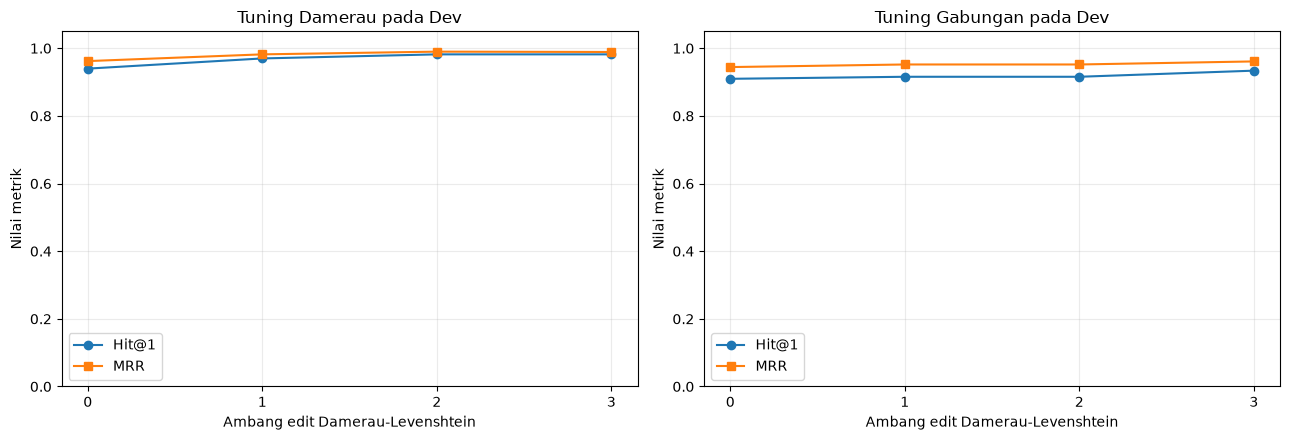

In [23]:
fig,axes = plt.subplots(1,2,figsize=(13,4.5))
for ax,metode in zip(axes,['Damerau','Gabungan']):
    sub = tuning_df[tuning_df['Metode']==metode]
    ax.plot(sub['Threshold'],sub['Hit@1'],marker='o',label='Hit@1')
    ax.plot(sub['Threshold'],sub['MRR'],marker='s',label='MRR')
    ax.set_title(f'Tuning {metode} pada Dev')
    ax.set_xticks(THRESHOLDS)
    ax.set_ylim(0,1.05)
    ax.set_xlabel('Ambang edit Damerau-Levenshtein')
    ax.set_ylabel('Nilai metrik')
    ax.grid(alpha=0.25); ax.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR/'fig_tuning_damerau_dev.png',dpi=180)
plt.show()


7. Evaluasi empat konfigurasi pada test dan per gaya, termasuk Fallback Rate

In [24]:
if not JALANKAN_TEST_FINAL:
    raise RuntimeError('Test set belum diaktifkan. Tetapkan JALANKAN_TEST_FINAL=True di Sel 1 saat evaluasi final.')

# Setiap detail dihitung ulang dengan korpus, preprocessing, dan tie-breaking yang sama.
# Tidak menghitung fallback dari CSV ringkasan yang tidak memiliki skor top-1.
detail_test = {
    'Baseline':evaluasi_detail(test_df,'Baseline'),
    'Kamus':evaluasi_detail(test_df,'Kamus'),
    'Damerau':evaluasi_detail(test_df,'Damerau',best_d2),
    'Gabungan':evaluasi_detail(test_df,'Gabungan',best_threshold)
}

# Validasi: urutan kueri harus sama untuk membandingkan 4 metode.
ids = test_df['query_id'].astype(str).tolist()
for nama,df in detail_test.items():
    if df['query_id'].tolist() != ids:
        raise ValueError(f'Urutan kueri pada {nama} tidak sesuai test set.')
    if not np.isfinite(df['skor_top1'].to_numpy(dtype=float)).all():
        raise ValueError(f'Skor BM25 {nama} mengandung NaN/Inf')

summary_rows = []
for nama in KONFIG:
    metrik = ringkas(detail_test[nama],T_BM25)
    label = LABEL[nama]
    if nama=='Damerau': label += f' (d <= {best_d2})'
    if nama=='Gabungan': label += f' (d <= {best_threshold})'
    summary_rows.append({'Konfigurasi':label, **metrik})
summary_test = pd.DataFrame(summary_rows)

# Penting: per_gaya_df dibangun lebih dahulu, termasuk kolom FallbackRate_*.
per_gaya_rows = []
for gaya in ORDER:
    parts = {k:df.loc[df['gaya_kueri']==gaya] for k,df in detail_test.items()}
    if not len(parts['Baseline']): continue
    satu = {'Gaya Kueri':gaya, 'n':len(parts['Baseline'])}
    for k in KONFIG:
        if len(parts[k])!=satu['n']:
            raise ValueError(f'Jumlah {gaya} pada {k} berbeda dari Baseline')
        met = ringkas(parts[k],T_BM25)
        satu[f'Hit@1_{k}'] = met['Hit@1']
        satu[f'MRR_{k}'] = met['MRR']
        satu[f'FallbackRate_{k}'] = met['Fallback Rate']
        satu[f'KueriFallback_{k}'] = met['Kueri_Fallback']
    per_gaya_rows.append(satu)
per_gaya_df = pd.DataFrame(per_gaya_rows)
if per_gaya_df.empty: raise ValueError('Tidak ada gaya kueri yang cocok dengan ORDER')

# Audit silang: fallback keseluruhan == agregat tertimbang fallback per gaya.
for i,k in enumerate(KONFIG):
    total = int(per_gaya_df[f'KueriFallback_{k}'].sum())
    if total != int(summary_test.iloc[i]['Kueri_Fallback']):
        raise AssertionError(f'Fallback keseluruhan/per gaya tidak konsisten: {k}')

print(f'=== Perbandingan Kinerja Keseluruhan pada Test Set (n={len(test_df)}) ===')
display(summary_test.round(4))
print('=== Perbandingan Per Gaya Kueri pada Test Set ===')
display(per_gaya_df.round(4))

# Audit opsional terhadap ringkasan lama. Tidak bergantung pada file lama agar tidak salah kolom.
path_lama = {
    'Kamus':ROOT/'Eksperiment1'/'hasil_exp1'/'hasil_ringkasan_kamus_test.csv',
    'Damerau':ROOT/'Eksperiment2'/'hasil_ringkasan_levenshtein_test.csv'
}
for nama,path in path_lama.items():
    if path.is_file():
        lama = pd.read_csv(path)
        if len(lama)>1 and {'Hit@1','MRR','n'}.issubset(lama.columns):
            baris = KONFIG.index(nama)
            beda = {metric:round(float(lama.iloc[1][metric])-float(summary_test.iloc[baris][metric]),6)
                    for metric in ['Hit@1','MRR']}
            if any(abs(x)>1e-6 for x in beda.values()):
                print(f'PERHATIAN: {nama} berbeda dari CSV lama:',beda)
                print('Periksa tie-breaking kosakata/kesamaan preprocessing; grafik memakai perhitungan seragam terbaru.')
            else:
                print(f'Audit {nama}: cocok dengan CSV lama.')
    else:
        print(f'CSV {nama} tidak ada; hasil tetap dihitung langsung dari dataset.')

summary_test.to_csv(OUTPUT_DIR/'hasil_ringkasan_empat_konfigurasi_test.csv',index=False)
per_gaya_df.to_csv(OUTPUT_DIR/'hasil_per_gaya_empat_konfigurasi_test.csv',index=False)
for nama,detail in detail_test.items():
    detail.assign(Fallback=(detail['skor_top1']<T_BM25)).to_csv(
        OUTPUT_DIR/f'detail_{nama.lower()}_test.csv',index=False)
print('Seluruh CSV evaluasi dan detail test disimpan di:',OUTPUT_DIR)


=== Perbandingan Kinerja Keseluruhan pada Test Set (n=499) ===


,Konfigurasi,Hit@1,Hit@3,Hit@5,MRR,Token_Terkoreksi,Rasio_Koreksi,n,Fallback Rate,Kueri_Fallback
0,Baseline (BM25 tanpa koreksi),0.9519,0.988,0.994,0.9698,0,0.0000,499,0.1343,67
1,BM25 + Normalisasi Kamus,0.8397,0.976,0.986,0.9044,899,0.1786,499,0.1122,56
2,BM25 + Damerau-Levenshtein (d <= 2),0.9699,0.988,0.996,0.9800,701,0.1393,499,0.0962,48
3,BM25 + Kamus + Damerau-Levenshtein (d <= 3),0.8617,0.984,0.990,0.9186,1517,0.3014,499,0.0541,27


=== Perbandingan Per Gaya Kueri pada Test Set ===


,Gaya Kueri,n,Hit@1_Baseline,MRR_Baseline,FallbackRate_Baseline,KueriFallback_Baseline,Hit@1_Kamus,MRR_Kamus,FallbackRate_Kamus,KueriFallback_Kamus,Hit@1_Damerau,MRR_Damerau,FallbackRate_Damerau,KueriFallback_Damerau,Hit@1_Gabungan,MRR_Gabungan,FallbackRate_Gabungan,KueriFallback_Gabungan
0,formal,59,0.9661,0.9753,0.0678,4,0.8644,0.9214,0.0678,4,0.9661,0.9752,0.0678,4,0.8814,0.9327,0.0508,3
1,informal,109,1.0000,1.0000,0.1009,11,0.8532,0.9148,0.0642,7,1.0000,1.0000,0.0734,8,0.8624,0.9216,0.0275,3
2,singkatan,107,0.9720,0.9825,0.1589,17,0.8785,0.9330,0.1028,11,0.9907,0.9930,0.1215,13,0.8972,0.9424,0.0748,8
3,parafrase,104,0.8654,0.9186,0.1058,11,0.7981,0.8720,0.0577,6,0.9038,0.9394,0.0962,10,0.7885,0.8696,0.0481,5
4,typo,120,0.9583,0.9727,0.2000,24,0.8167,0.8892,0.2333,28,0.9833,0.9879,0.1083,13,0.8833,0.9301,0.0667,8


Audit Kamus: cocok dengan CSV lama.
Audit Damerau: cocok dengan CSV lama.
Seluruh CSV evaluasi dan detail test disimpan di: D:\Folder KULIAH\Sistem Temu Kembali\Artikel (1)\Eksperiment3\hasil_exp3


8.Visualisasi empat konfigurasi

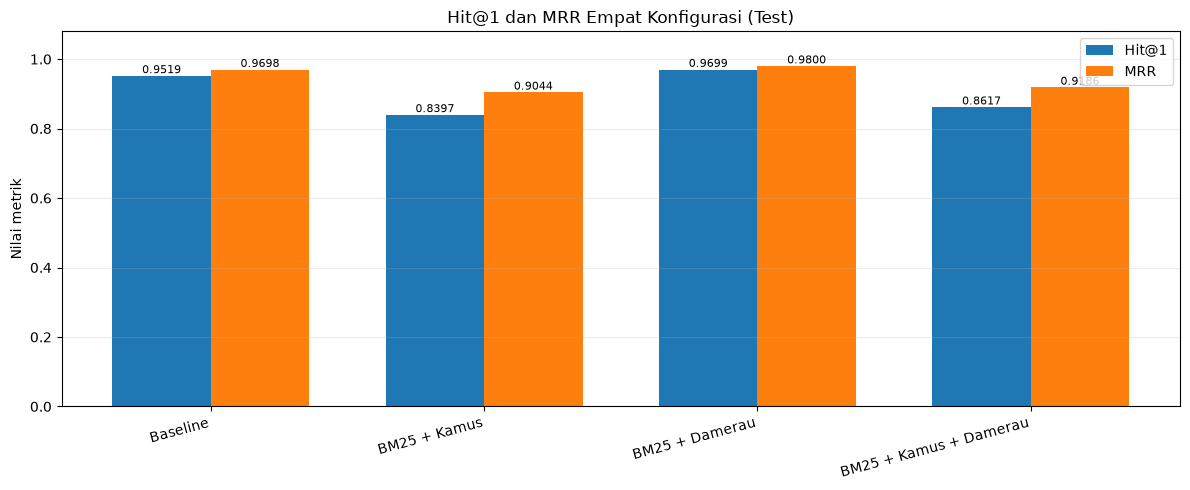

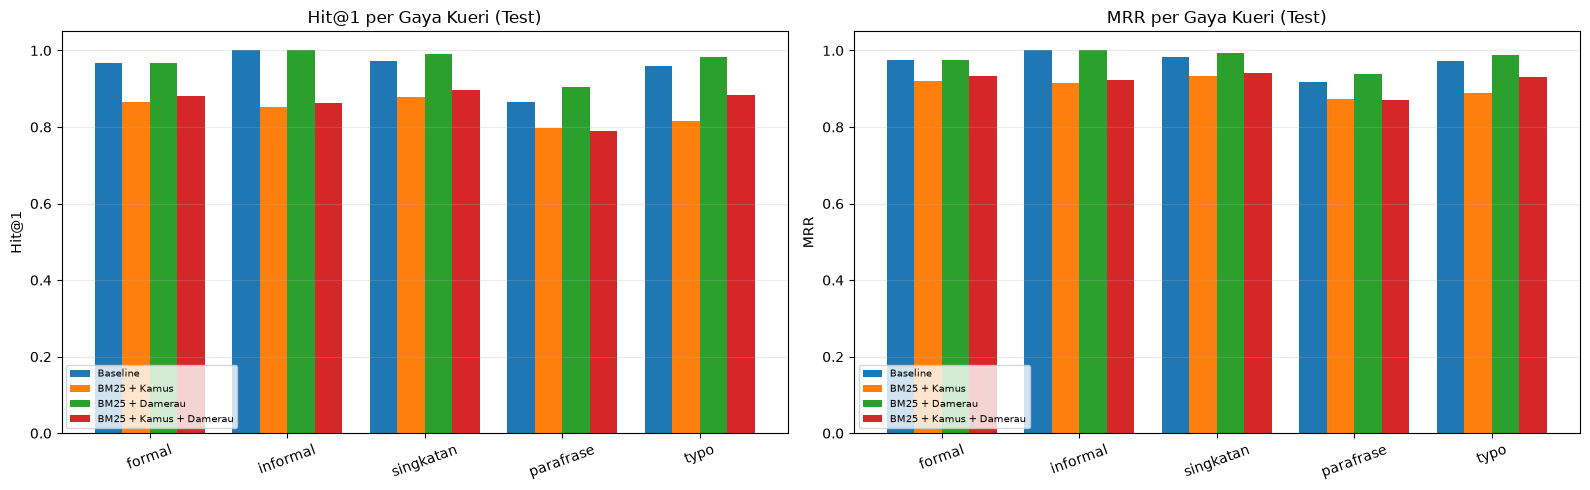

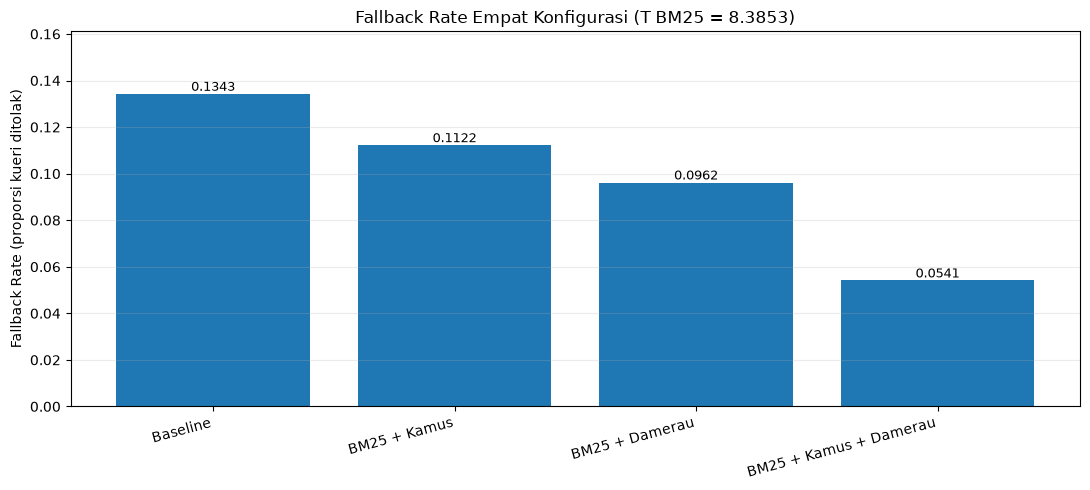

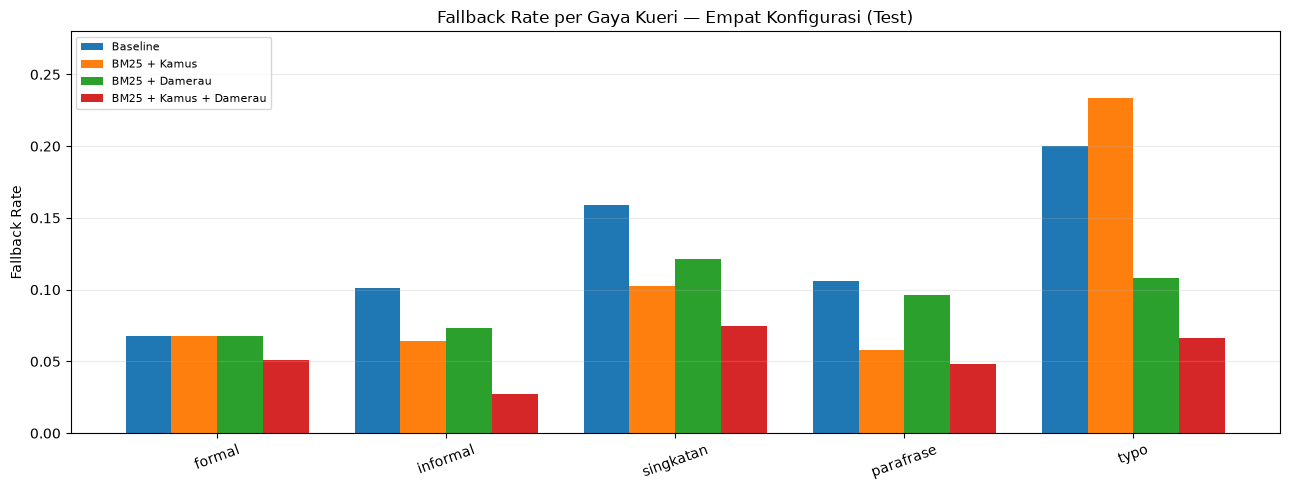

In [25]:
plot_specs = [('Baseline','Baseline'),('Kamus','BM25 + Kamus'),
              ('Damerau','BM25 + Damerau'),('Gabungan','BM25 + Kamus + Damerau')]
label_singkat = [label for _,label in plot_specs]

# (A) Hit@1 dan MRR keseluruhan.
x = np.arange(len(summary_test)); w = .36
fig,ax = plt.subplots(figsize=(12,5))
for offset,metrik in [(-w/2,'Hit@1'),(w/2,'MRR')]:
    bars=ax.bar(x+offset,summary_test[metrik],w,label=metrik)
    for bar in bars:
        ax.annotate(f'{bar.get_height():.4f}',
                    (bar.get_x()+bar.get_width()/2,bar.get_height()),
                    ha='center',va='bottom',fontsize=8)
ax.set_xticks(x,label_singkat,rotation=15,ha='right')
ax.set_ylabel('Nilai metrik'); ax.set_ylim(0,1.08)
ax.set_title('Hit@1 dan MRR Empat Konfigurasi (Test)')
ax.grid(axis='y',alpha=.25); ax.legend()
plt.tight_layout(); plt.savefig(OUTPUT_DIR/'fig_empat_konfigurasi_keseluruhan_test.png',dpi=180); plt.show()

# (B) Per gaya: Hit@1 dan MRR.
x=np.arange(len(per_gaya_df)); w=.2
fig,axes=plt.subplots(1,2,figsize=(16,5))
for ax,metrik in zip(axes,['Hit@1','MRR']):
    for j,(k,label) in enumerate(plot_specs):
        ax.bar(x+(j-1.5)*w,per_gaya_df[f'{metrik}_{k}'],w,label=label)
    ax.set_xticks(x,per_gaya_df['Gaya Kueri'],rotation=20)
    ax.set_ylim(0,1.05); ax.set_ylabel(metrik)
    ax.set_title(f'{metrik} per Gaya Kueri (Test)'); ax.grid(axis='y',alpha=.25)
    ax.legend(fontsize=7,loc='lower left')
plt.tight_layout();plt.savefig(OUTPUT_DIR/'fig_empat_konfigurasi_per_gaya_test.png',dpi=180);plt.show()

# (C) Fallback Rate empat konfigurasi (keseluruhan).
fig,ax=plt.subplots(figsize=(11,5))
x=np.arange(4)
bars=ax.bar(x,summary_test['Fallback Rate'])
ax.set_xticks(x,label_singkat,rotation=15,ha='right')
ax.set_ylim(0,max(.10,float(summary_test['Fallback Rate'].max())*1.2))
ax.set_ylabel('Fallback Rate (proporsi kueri ditolak)')
ax.set_title(f'Fallback Rate Empat Konfigurasi (T BM25 = {T_BM25:.4f})')
for bar in bars:
    ax.annotate(f'{bar.get_height():.4f}',(bar.get_x()+bar.get_width()/2,bar.get_height()),
                ha='center',va='bottom',fontsize=9)
ax.grid(axis='y',alpha=.25)
plt.tight_layout();plt.savefig(OUTPUT_DIR/'fig_fallback_empat_konfigurasi_test.png',dpi=180);plt.show()

# (D) Fallback Rate per gaya. Kolom ini SUDAH dibuat di Sel 7.
cols = [f'FallbackRate_{k}' for k,_ in plot_specs]
missing = set(cols)-set(per_gaya_df.columns)
if missing: raise KeyError(f'Kolom per gaya belum tersedia: {sorted(missing)}. Jalankan Sel 7 terlebih dahulu.')
x=np.arange(len(per_gaya_df)); w=.2
fig,ax=plt.subplots(figsize=(13,5))
for j,(k,label) in enumerate(plot_specs):
    ax.bar(x+(j-1.5)*w,per_gaya_df[f'FallbackRate_{k}'],w,label=label)
ax.set_xticks(x,per_gaya_df['Gaya Kueri'],rotation=20)
ax.set_ylim(0,max(.1,float(per_gaya_df[cols].to_numpy().max())*1.2))
ax.set_ylabel('Fallback Rate');ax.set_title('Fallback Rate per Gaya Kueri — Empat Konfigurasi (Test)')
ax.legend(fontsize=8);ax.grid(axis='y',alpha=.25)
plt.tight_layout();plt.savefig(OUTPUT_DIR/'fig_fallback_per_gaya_empat_konfigurasi_test.png',dpi=180);plt.show()


9. Audit perubahan peringkat dan koreksi berlebih

In [26]:
# Bandingkan rank Baseline vs Gabungan untuk query_id yang sama.
a = detail_test['Baseline'][['query_id','gaya_kueri','query_text','peringkat_benar','hit1']].rename(
    columns={'peringkat_benar':'rank_baseline','hit1':'hit_baseline'})
b = detail_test['Gabungan'][['query_id','peringkat_benar','hit1','normalisasi_kamus','koreksi_damerau','skor_top1']].rename(
    columns={'peringkat_benar':'rank_gabungan','hit1':'hit_gabungan'})
audit = a.merge(b,on='query_id',validate='one_to_one')
audit['delta_rank'] = audit['rank_baseline']-audit['rank_gabungan']
audit['Status'] = np.select([audit['delta_rank']>0,audit['delta_rank']<0],
                            ['Membaik','Memburuk'],default='Tetap')
audit['Fallback_Gabungan'] = audit['skor_top1'] < T_BM25
print('=== Perubahan Peringkat Baseline ke Gabungan ===')
display(audit['Status'].value_counts().rename_axis('Status').reset_index(name='Jumlah'))
print('Contoh kueri memburuk (potensi koreksi berlebihan):')
display(audit.loc[audit['Status']=='Memburuk'].head(12))
audit.to_csv(OUTPUT_DIR/'audit_perubahan_peringkat_gabungan_test.csv',index=False)
print('Selesai. Semua hasil tersimpan pada:',OUTPUT_DIR)


=== Perubahan Peringkat Baseline ke Gabungan ===


,Status,Jumlah
0,Tetap,433
1,Memburuk,58
2,Membaik,8


Contoh kueri memburuk (potensi koreksi berlebihan):


,query_id,gaya_kueri,query_text,rank_baseline,hit_baseline,rank_gabungan,hit_gabungan,normalisasi_kamus,koreksi_damerau,skor_top1,delta_rank,Status,Fallback_Gabungan
5,Q0040,parafrase,"akun tim saya belum di verifikasi, saya tidak bisa menambahkannya sebagai anggota tim",2,0,3,0,,tim -> nim (d=1) | tim -> nim (d=1),7.044216,-1,Memburuk,True
46,Q0006,informal,akun sipi ku belum terverifikasi,1,1,3,0,sipi -> sistem informasi praktik industri,,4.869811,-2,Memburuk,True
50,Q0345,singkatan,"misi, apabila pihak perusahaan tdk bersedia menandatangani SPK dan IA, dokumen apa yg prlu diunggah sebagai gantinya",1,1,2,0,tdk -> tidak | spk -> surat pernyataan kerjasama | ia -> implementation arrangement | yg -> yang | prlu -> perlu,misi -> isi (d=1) | apabila -> ambil (d=3) | diunggah -> diunduh (d=3),26.114260,-1,Memburuk,False
56,Q0256,parafrase,"Izin bertanya, harusnya saya 3 orang ibu, tapi baru 2 orang dan sudah disetujui admin, jadi tidak bisa menambahkan t...",1,1,2,0,,bertanya -> berapa (d=3) | orang -> ulang (d=2) | ibu -> itu (d=1) | orang -> ulang (d=2),7.218260,-1,Memburuk,True
57,Q0082,informal,cara pengajuan selesai pi gimana di sipi,1,1,2,0,pi -> praktik industri | gimana -> bagaimana | sipi -> sistem informasi praktik industri,,8.602652,-1,Memburuk,False
61,Q0060,informal,"klo perusahaan gamau ttd spk ia, upload apa gantinya",1,1,2,0,klo -> kalau | ttd -> tanda tangan | spk -> surat pernyataan kerjasama | ia -> implementation arrangement,gamau -> nama (d=2),17.064244,-1,Memburuk,False
65,Q0061,parafrase,dibagian SPK dan IA bertanda wajib apakah yang diupload adalah file laporan PI juga jadi file yang diupload double,1,1,3,0,spk -> surat pernyataan kerjasama | ia -> implementation arrangement | pi -> praktik industri,double -> google (d=3),17.085864,-2,Memburuk,False
78,Q0476,typo,bagaimana cara melakkuan pengajuan Selesai PI di SiPi,1,1,3,0,pi -> praktik industri | sipi -> sistem informasi praktik industri,melakkuan -> melakukan (d=1),8.602652,-2,Memburuk,False
79,Q0223,parafrase,Seperti apa langkah membuat pengelompokan dan memilih Lokasi PI di SiPi,1,1,2,0,pi -> praktik industri | sipi -> sistem informasi praktik industri,langkah -> lengkap (d=2),12.416566,-1,Memburuk,False
85,Q0507,parafrase,"Mohon info, dokumen apa saja yang perlu disiapkan sebelum pelaksanaan seminar PI",1,1,2,0,pi -> praktik industri,,13.196203,-1,Memburuk,False


Selesai. Semua hasil tersimpan pada: D:\Folder KULIAH\Sistem Temu Kembali\Artikel (1)\Eksperiment3\hasil_exp3
